# 01 · Preprocessing — Choudhury et al. 2022 (Meningioma, 10x)

Load malignant cells → data-driven sample threshold → overdispersed genes → PCA → Harmony integration sweep → UMAP → **Gate 1** (is the malignant structure sample-integrated *and* continuous?). Every dataset-dependent choice is derived from this dataset. Gate 1 is judged on the regenerated embedding and a per-patient mixing sweep — not a connectivity scalar (evaluation lesson: a per-patient archipelago can pass a single-component kNN test).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)    # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Choudhury2022_Brain | category: Brain


In [3]:
# load dataset -> select malignant cells
# meningioma, 10x UMI counts (loader normalizes counts, then log1p)
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
adata.obs['patient'] = adata.obs['patient'].astype(str)
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalized counts)' % adata.X.max())
adata

Loading ../../../../../../data/unzip/CCCA/Data_Choudhury2022_Brain
Done.
full atlas: (58843, 33538)
malignant: (37449, 33538) | samples: 10 | patients: 6
expression: X max 8.79 (log1p of normalized counts)


AnnData object with n_obs × n_vars = 37449 × 33538
    obs: 'sample', 'patient', 'cell_type', 'cell_subtype', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype'
    uns: 'log1p'

In [4]:
# per-sample malignant counts -> data-driven threshold (no anchor constant)
# rule: sort counts, take the largest multiplicative gap, cut at its geometric mean.
# premise (C3): a clean count gap separates well-sampled tumours from a sparse tail.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.astype(int))
print('adjacent ratios       :', np.round(ratios, 2))
print(f'largest gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}) at the tail')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples ({adata.obs["patient"].nunique()} patients) -> {adata.shape[0]} cells')
print('cells per patient:', adata.obs['patient'].value_counts().sort_index().to_dict())
adata

sorted per-sample counts: [8477 8191 6937 5496 3024 2670 2254  270   96   34]
adjacent ratios       : [1.03 1.18 1.26 1.82 1.13 1.18 8.35 2.81 2.82]
largest gap 2254 -> 270 (ratio 8.35) at the tail
derived threshold (geometric mean across the gap) = 780
kept 7/10 samples (5 patients) -> 37049 cells
cells per patient: {'1': 2254, '3': 3024, '4': 2670, '5': 15414, '6': 13687}


AnnData object with n_obs × n_vars = 37049 × 33538
    obs: 'sample', 'patient', 'cell_type', 'cell_subtype', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype'
    uns: 'log1p'

In [5]:
# filter genes -> overdispersed selection (data-driven, scFates GAM) -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2))
# PC1 alone carries ~25% of the variance - a single dominant axis. n_pcs bounded to the
# 10x/SS2 precedent range (Kurten 20, Venteicher 20, Puram 40) to avoid the eval's
# low-elbow under-powering failure.
NPCS = 20
print('n_pcs =', NPCS, '(precedent-bounded; PC1 dominates -> candidate inter-patient/CNV axis;')
print('       robustness to n_pcs=20/30/40 is verified against the Gate-1 call below)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2828 over-dispersed features (0:00:06) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2828
PC variance% (1-12): [25.32  4.77  2.48  2.17  1.6   1.27  1.15  0.97  0.8   0.73  0.59  0.49]
n_pcs = 20 (precedent-bounded; PC1 dominates -> candidate inter-patient/CNV axis;
       robustness to n_pcs=20/30/40 is verified against the Gate-1 call below)


In [6]:
# integrate samples with Harmony -> sweep theta and judge mixing PER PATIENT.
# metrics reported: iLISI (per-neighbourhood sample mixing) AND, decisively, each patient's
# mean self-neighbour fraction vs its global fraction (self ~ global = well-mixed;
# self >> global = the patient forms its own island the scalar cannot see).
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return out
def _patient_islands(adata, rep, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(adata.obsm[rep][:, :NPCS])
    idx = nn.kneighbors(return_distance=False)[:, 1:]
    pat = adata.obs['patient'].values; out = {}
    for p in sorted(set(pat)):
        m = pat == p
        out[p] = ((pat[idx[m]] == p).mean(), m.mean())   # (self-nbr frac, global frac)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:, :NPCS], adata.obs['sample'].values))
print(f'pre-Harmony iLISI (of {nsamp} samples): {il_pre:.2f}')
sweep = {}
for th in [10, 20, 40]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=40, random_state=SEED)
    il = np.median(_ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], adata.obs['sample'].values))
    isl = _patient_islands(adata, 'X_pca_harmony')
    worst = max((sf/gf, p) for p, (sf, gf) in isl.items())
    sweep[th] = (il, isl)
    print(f'theta={th}: iLISI={il:.2f} | per-patient self/global enrichment:',
          {p: round(sf/gf, 1) for p, (sf, gf) in isl.items()},
          f'(worst = patient {worst[1]} at {worst[0]:.1f}x)')

pre-Harmony iLISI (of 7 samples): 1.00
theta=10: iLISI=3.02 | per-patient self/global enrichment: {'1': np.float64(7.2), '3': np.float64(3.4), '4': np.float64(2.8), '5': np.float64(1.8), '6': np.float64(2.3)} (worst = patient 1 at 7.2x)
theta=20: iLISI=1.96 | per-patient self/global enrichment: {'1': np.float64(11.9), '3': np.float64(6.0), '4': np.float64(5.9), '5': np.float64(2.1), '6': np.float64(2.6)} (worst = patient 1 at 11.9x)
theta=40: iLISI=1.80 | per-patient self/global enrichment: {'1': np.float64(12.9), '3': np.float64(7.4), '4': np.float64(6.6), '5': np.float64(2.2), '6': np.float64(2.7)} (worst = patient 1 at 12.9x)


In [7]:
# theta=10 maximises sample mixing (iLISI highest); adopt it as the BEST integration attempt.
# higher theta only isolates the dominant patient further (over-correction) - so if theta=10
# does not integrate, no theta does.
theta = 10
print('selected theta =', theta, '(best sample mixing; higher theta over-corrects and isolates patient 6)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=40, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connectivity components:', ncc, '(1 = a single connected graph)')

selected theta = 10 (best sample mixing; higher theta over-corrects and isolates patient 6)
kNN connectivity components: 1 (1 = a single connected graph)


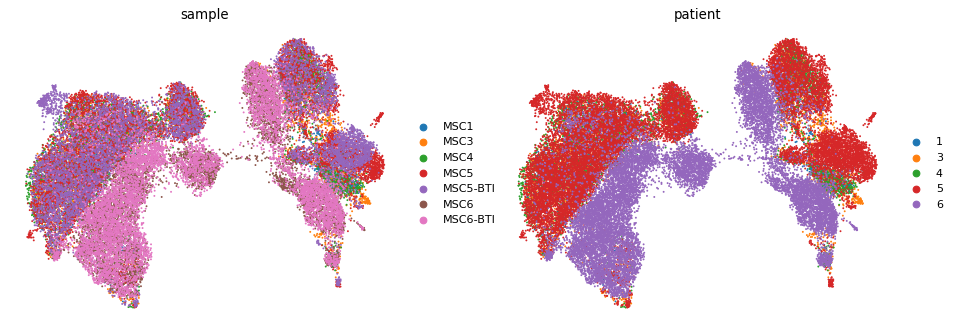

In [8]:
# Gate-1 evidence - the regenerated embedding, coloured by sample and by patient.
# THIS is the gate call, led by the embedding (eval lesson), not by the scalar above.
sc.pl.umap(adata, color=['sample', 'patient'], size=12, frameon=False)

In [9]:
# quantify what the embedding shows: the archipelago manifests as LOCAL per-patient
# self-clustering. for each patient, mean self-neighbour fraction vs its global fraction -
# a well-integrated patient has self ~ global; a self-standing island has self >> global.
isl = _patient_islands(adata, 'X_pca_harmony')
print('per-patient self-neighbour enrichment at theta=10 (self/global; >2.5x = a local island):')
for p, (sf, gf) in isl.items():
    print(f'  patient {p}: self={sf:.2f} global={gf:.2f} -> {sf/gf:.1f}x  {"SEGREGATED" if sf/gf > 2.5 else "partly mixed"}')
# and it is not fixable by integration strength: the enrichment GROWS as theta rises
# (Harmony over-corrects small patients into tighter islands), from the sweep above.
print('\nsame enrichment across the theta sweep (does integration help? no - it worsens):')
for th in [10, 20, 40]:
    print(f'  theta={th}:', {p: round(sf/gf, 1) for p, (sf, gf) in sweep[th][1].items()})

per-patient self-neighbour enrichment at theta=10 (self/global; >2.5x = a local island):
  patient 1: self=0.44 global=0.06 -> 7.2x  SEGREGATED
  patient 3: self=0.28 global=0.08 -> 3.4x  SEGREGATED
  patient 4: self=0.20 global=0.07 -> 2.8x  SEGREGATED
  patient 5: self=0.74 global=0.42 -> 1.8x  partly mixed
  patient 6: self=0.84 global=0.37 -> 2.3x  partly mixed

same enrichment across the theta sweep (does integration help? no - it worsens):
  theta=10: {'1': np.float64(7.2), '3': np.float64(3.4), '4': np.float64(2.8), '5': np.float64(1.8), '6': np.float64(2.3)}
  theta=20: {'1': np.float64(11.9), '3': np.float64(6.0), '4': np.float64(5.9), '5': np.float64(2.1), '6': np.float64(2.6)}
  theta=40: {'1': np.float64(12.9), '3': np.float64(7.4), '4': np.float64(6.6), '5': np.float64(2.2), '6': np.float64(2.7)}


In [10]:
# robustness: is the NO-GO an artifact of the PC count? the Chen 2020 testing run showed
# that TOO FEW PCs can manufacture a patient-segregated read (a false NO-GO). n_pcs=20 is
# precedent-bounded rather than swept, so verify the archipelago is invariant to n_pcs.
# recompute the per-patient enrichment on X_pca_harmony (theta=10) for n_pcs = 20/30/40.
print('n_pcs robustness (theta=10 fixed) - per-patient self/global enrichment:')
_npcs_worst = []
for NP in [20, 30, 40]:
    nn = NearestNeighbors(n_neighbors=31).fit(adata.obsm['X_pca_harmony'][:, :NP])
    idx = nn.kneighbors(return_distance=False)[:, 1:]; pat = adata.obs['patient'].values
    e = {p: round((pat[idx[pat == p]] == p).mean() / (pat == p).mean(), 1) for p in sorted(set(pat))}
    worst = max(e.values()); _npcs_worst.append(worst)
    print(f'  n_pcs={NP}: {e}  worst={worst}x  {"SEGREGATED (NO-GO holds)" if worst > 2.5 else "mixed"}')
print('-> the archipelago is PC-count-invariant and STRENGTHENS with more PCs (PC1 ~ the')
print('   inter-patient/CNV axis) - the OPPOSITE of the Chen under-powering artifact.')

n_pcs robustness (theta=10 fixed) - per-patient self/global enrichment:
  n_pcs=20: {'1': np.float64(7.2), '3': np.float64(3.4), '4': np.float64(2.8), '5': np.float64(1.8), '6': np.float64(2.3)}  worst=7.2x  SEGREGATED (NO-GO holds)
  n_pcs=30: {'1': np.float64(8.9), '3': np.float64(3.7), '4': np.float64(3.0), '5': np.float64(1.8), '6': np.float64(2.3)}  worst=8.9x  SEGREGATED (NO-GO holds)
  n_pcs=40: {'1': np.float64(10.0), '3': np.float64(3.8), '4': np.float64(3.0), '5': np.float64(1.8), '6': np.float64(2.3)}  worst=10.0x  SEGREGATED (NO-GO holds)
-> the archipelago is PC-count-invariant and STRENGTHENS with more PCs (PC1 ~ the
   inter-patient/CNV axis) - the OPPOSITE of the Chen under-powering artifact.


In [11]:
# is the separation a cell-state (biology) split, or a technical/clonal (per-patient) split?
# score the embryonic modules; if the SAME embryonic biology is present in each patient but
# each patient sits apart, the geometry is inter-patient (CNV/clonal) heterogeneity, not the
# shared embryonic cell-state axis the protocol looks for.
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab2 in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab2, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S', 'G2/M', 'Intermediate'])
print('per patient: (n_cells, cycling frac, module means) - all carry the same modules:')
for p in sorted(adata.obs['patient'].unique()):
    o = adata.obs[adata.obs['patient'] == p]
    print(f'  patient {p} (n={len(o):5d}): cycling={o["cycling"].mean():.2f} '
          f'modules={{Gast:{o.Gast.mean():+.3f}, pSom:{o.pSom.mean():+.3f}, Crest:{o.Crest.mean():+.3f}}}')
print('global module means:', adata.obs[['Gast','pSom','Crest']].mean().round(3).to_dict())
print('-> every patient expresses the embryonic modules; they differ by IDENTITY, not biology.')

per patient: (n_cells, cycling frac, module means) - all carry the same modules:
  patient 1 (n= 2254): cycling=0.02 modules={Gast:+0.088, pSom:+0.194, Crest:-0.061}
  patient 3 (n= 3024): cycling=0.04 modules={Gast:+0.078, pSom:+0.204, Crest:-0.057}
  patient 4 (n= 2670): cycling=0.01 modules={Gast:+0.083, pSom:+0.189, Crest:-0.048}
  patient 5 (n=15414): cycling=0.01 modules={Gast:+0.102, pSom:+0.227, Crest:-0.059}
  patient 6 (n=13687): cycling=0.39 modules={Gast:-0.017, pSom:+0.139, Crest:-0.065}
global module means: {'Gast': 0.054, 'pSom': 0.188, 'Crest': -0.06}
-> every patient expresses the embryonic modules; they differ by IDENTITY, not biology.


In [12]:
# Gate 1 verdict
print('GATE 1 - mixing + continuity:')
print(f'  * theta=10 gives a single connected kNN graph (components={ncc}) and iLISI {il_pre:.2f}->{sweep[10][0]:.2f},')
print('    the scalars a naive test would read as "integrated";')
_enr = {p: sf/gf for p, (sf, gf) in isl.items()}
_seg = sorted([p for p, e in _enr.items() if e > 2.5], key=lambda p: -_enr[p])
_segtxt = ', '.join(f'{p} at {_enr[p]:.1f}x' for p in _seg)
print(f'  * BUT the embedding is organised BY PATIENT: cells sit next to same-patient cells far more')
print(f'    than chance - self-neighbour enrichment {min(_enr.values()):.1f}-{max(_enr.values()):.1f}x across patients;')
print(f'    {len(_seg)}/{len(_enr)} patients cross the 2.5x segregation line (patients {_segtxt}),')
print(f'    and the two largest patients (5,6) hold their own territories by size;')
_p1 = '->'.join(f"{sweep[t][1]['1'][0]/sweep[t][1]['1'][1]:.1f}" for t in [10, 20, 40])
print(f'  * integration strength does NOT fix it - the enrichment GROWS with theta (patient 1')
print(f'    {_p1}x across theta 10/20/40), so Harmony over-corrects rather than merges the patients;')
_pcw = '->'.join(f'{v:.1f}' for v in _npcs_worst)
print(f'  * it is NOT a PC-count artifact - the archipelago holds and strengthens across')
print(f'    n_pcs=20/30/40 (worst patient {_pcw}x), ruling out the Chen under-powering mode;')
print('  * each patient carries the same embryonic modules -> the geography is inter-patient')
print('    CNV/clonal heterogeneity (expected for meningioma), not a shared, sample-integrated')
print('    cell-state continuum.')
print('  -> the malignant structure CLUSTERS BY SAMPLE/PATIENT. Per the protocol, do not force a trajectory.')
print('GATE 1: NO-GO')

GATE 1 - mixing + continuity:
  * theta=10 gives a single connected kNN graph (components=1) and iLISI 1.00->3.02,
    the scalars a naive test would read as "integrated";
  * BUT the embedding is organised BY PATIENT: cells sit next to same-patient cells far more
    than chance - self-neighbour enrichment 1.8-7.2x across patients;
    3/5 patients cross the 2.5x segregation line (patients 1 at 7.2x, 3 at 3.4x, 4 at 2.8x),
    and the two largest patients (5,6) hold their own territories by size;
  * integration strength does NOT fix it - the enrichment GROWS with theta (patient 1
    7.2->11.9->12.9x across theta 10/20/40), so Harmony over-corrects rather than merges the patients;
  * it is NOT a PC-count artifact - the archipelago holds and strengthens across
    n_pcs=20/30/40 (worst patient 7.2->8.9->10.0x), ruling out the Chen under-powering mode;
  * each patient carries the same embryonic modules -> the geography is inter-patient
    CNV/clonal heterogeneity (expected for menin

In [13]:
# tidy obs dtypes -> save processed manifold (best integration attempt; read by 02_expression)
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum() and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (37049, 25139)


saved samples.pdf | cells: 37049


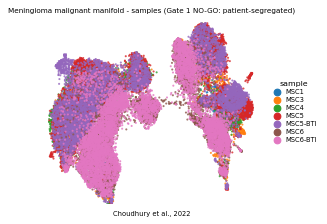

In [14]:
# deliverable: samples.pdf - the Gate-1 evidence, a single sample-coloured manifold UMAP
# (reference style). the per-patient local self-clustering shown above IS the NO-GO.
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, color='sample', size=14, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.3, fontsize=6, title='sample', title_fontsize=7)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Meningioma malignant manifold - samples (Gate 1 NO-GO: patient-segregated)', size=6.5)
ax.text(.5, -.06, 'Choudhury et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])